In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
from pathlib import Path
import pandas as pd

# CSV files are directly inside the project folder
DATA_DIR = Path.cwd()

# Output folder for saving results
OUTPUT_DIR = DATA_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# File paths
train_path = DATA_DIR / "train.csv"
store_path = DATA_DIR / "store.csv"
test_path = DATA_DIR / "test.csv"

# Check whether files exist
for file_path in [train_path, store_path, test_path]:
    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

# Load datasets
sales_df = pd.read_csv(train_path, parse_dates=["Date"])
store_df = pd.read_csv(store_path)
test_df = pd.read_csv(test_path, parse_dates=["Date"])

# Display dataset details
print("Training data shape:", sales_df.shape)
print("Store data shape:", store_df.shape)
print("Test data shape:", test_df.shape)

display(sales_df.head())
display(store_df.head())
display(test_df.head())

C:\Users\ADS2609026\AppData\Local\Temp\53\ipykernel_14376\4169079270.py:22: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(train_path, parse_dates=["Date"])


Training data shape: (1017209, 9)
Store data shape: (1115, 10)
Test data shape: (41088, 8)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [4]:
print("Training dataset information:")
sales_df.info()

print("\nMissing values in training data:")
display(
    sales_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nSales summary:")
display(sales_df["Sales"].describe())

print("\nStore dataset missing values:")
display(
    store_df.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

Training dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), object(1)
memory usage: 69.8+ MB

Missing values in training data:


,Missing_Count
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0



Duplicate rows: 0

Sales summary:


count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64


Store dataset missing values:


,Missing_Count
PromoInterval,544
Promo2SinceYear,544
Promo2SinceWeek,544
CompetitionOpenSinceYear,354
CompetitionOpenSinceMonth,354
CompetitionDistance,3
StoreType,0
Store,0
Assortment,0
Promo2,0


In [5]:
data = sales_df.merge(
    store_df,
    on="Store",
    how="left",
    validate="many_to_one"
)

print("Merged dataset shape:", data.shape)

display(data.head())

Merged dataset shape: (1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [6]:
data["Date"] = pd.to_datetime(
    data["Date"],
    errors="coerce"
)
  
data = data.dropna(
    subset=["Date", "Sales", "Store"]
).copy()

data = data.drop_duplicates(
    subset=["Store", "Date"]
).copy() 

data["Sales"] = pd.to_numeric(
    data["Sales"],
    errors="coerce"
)

data = data.dropna(subset=["Sales"]).copy()

data = data.sort_values("Date").reset_index(drop=True)

# Extract useful date-related features.
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Day"] = data["Date"].dt.day 
data["WeekOfYear"] = data["Date"].dt.isocalendar().week.astype(int)

# DayOfWeek is already provided in the original dataset.
# Retain it and use it as an explanatory feature.

print("Cleaned dataset shape:", data.shape)

print("Date range:")
print(data["Date"].min(), "to", data["Date"].max())

print("\nMissing values after initial cleaning:")
display(
    data.isnull()
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .to_frame("Missing_Count")
)

Cleaned dataset shape: (1017209, 22)
Date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Missing values after initial cleaning:


,Missing_Count
PromoInterval,508031
Promo2SinceYear,508031
Promo2SinceWeek,508031
CompetitionOpenSinceMonth,323348
CompetitionOpenSinceYear,323348
CompetitionDistance,2642
Open,0
Customers,0
Sales,0
Date,0


In [7]:
data = data[
    (data["Open"] == 1) &
    (data["Sales"] > 0)
].copy()

data = data.sort_values("Date").reset_index(drop=True)

# Reserve the latest two months for final testing.
test_start_date = (
    data["Date"].max().normalize()
    - pd.DateOffset(months=2)
)

# The final test set is strictly later than the development period.
development_data = data[
    data["Date"] <= test_start_date
].copy()

test_data = data[
    data["Date"] > test_start_date
].copy()

print("Development observations:", len(development_data))
print("Test observations:", len(test_data))

print("\nDevelopment period:")
print(
    development_data["Date"].min(),
    "to",
    development_data["Date"].max()
)

print("\nTest period:")
print(
    test_data["Date"].min(),
    "to",
    test_data["Date"].max()
)

Development observations: 785727
Test observations: 58611

Development period:
2013-01-01 00:00:00 to 2015-05-31 00:00:00

Test period:
2015-06-01 00:00:00 to 2015-07-31 00:00:00


In [8]:
validation_start_date = (
    development_data["Date"].max().normalize()
    - pd.DateOffset(months=1)
)

train_data = development_data[
    development_data["Date"] <= validation_start_date
].copy()

validation_data = development_data[
    development_data["Date"] > validation_start_date
].copy()

print("Training observations:", len(train_data))
print("Validation observations:", len(validation_data))
print("Final test observations:", len(test_data))

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nValidation period:")
print(
    validation_data["Date"].min(),
    "to",
    validation_data["Date"].max()
)

Training observations: 759848
Validation observations: 25879
Final test observations: 58611

Training period:
2013-01-01 00:00:00 to 2015-04-30 00:00:00

Validation period:
2015-05-01 00:00:00 to 2015-05-31 00:00:00


In [9]:
target_column = "Sales"

excluded_columns = [
    "Sales",
    "Customers",
    "Date",
    "Open"
]

# Open is constant in our filtered dataset.
# Customers is excluded because it is not available
# for future forecasting in the official competition test set.

feature_columns = [
    column
    for column in train_data.columns
    if column not in excluded_columns
]

X_train_raw = train_data[feature_columns].copy()
X_validation_raw = validation_data[feature_columns].copy()
X_test_raw = test_data[feature_columns].copy()

y_train = train_data[target_column].copy()
y_validation = validation_data[target_column].copy()
y_test = test_data[target_column].copy()

categorical_columns = [
    column
    for column in [
        "StateHoliday",
        "StoreType",
        "Assortment",
        "PromoInterval"
    ]
    if column in feature_columns
]

for frame in [
    X_train_raw,
    X_validation_raw,
    X_test_raw
]:
    for column in categorical_columns:
        frame[column] = (
            frame[column]
            .fillna("Unknown")
            .astype(str)
        )

    numeric_columns = frame.select_dtypes(
        include=np.number
    ).columns

    frame[numeric_columns] = frame[numeric_columns].replace(
        [np.inf, -np.inf],
        np.nan
    )

# Learn numeric imputation values from training data only.
numeric_columns = X_train_raw.select_dtypes(
    include=np.number
).columns

numeric_medians = X_train_raw[numeric_columns].median()

X_train_raw[numeric_columns] = (
    X_train_raw[numeric_columns]
    .fillna(numeric_medians)
)

X_validation_raw[numeric_columns] = (
    X_validation_raw[numeric_columns]
    .fillna(numeric_medians)
)

X_test_raw[numeric_columns] = (
    X_test_raw[numeric_columns]
    .fillna(numeric_medians)
)

# Convert categorical columns to one-hot encoded features.
X_train = pd.get_dummies(
    X_train_raw,
    columns=categorical_columns,
    dtype=np.uint8
)

X_validation = pd.get_dummies(
    X_validation_raw,
    columns=categorical_columns,
    dtype=np.uint8
)

X_test = pd.get_dummies(
    X_test_raw,
    columns=categorical_columns,
    dtype=np.uint8
)

# Align columns to ensure all datasets have the same feature schema.
X_validation = X_validation.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Convert numerical features to consistent types.
X_train = X_train.astype(np.float32)
X_validation = X_validation.astype(np.float32)
X_test = X_test.astype(np.float32)

print("Training feature matrix:", X_train.shape)
print("Validation feature matrix:", X_validation.shape)
print("Test feature matrix:", X_test.shape)

print("\nTarget shapes:")
print(y_train.shape, y_validation.shape, y_test.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

Training feature matrix: (759848, 29)
Validation feature matrix: (25879, 29)
Test feature matrix: (58611, 29)

Target shapes:
(759848,) (25879,) (58611,)

Feature columns:
['Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Year', 'Month', 'Day', 'WeekOfYear', 'StateHoliday_0', 'StateHoliday_a', 'StateHoliday_b', 'StateHoliday_c', 'StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_a', 'Assortment_b', 'Assortment_c', 'PromoInterval_Feb,May,Aug,Nov', 'PromoInterval_Jan,Apr,Jul,Oct', 'PromoInterval_Mar,Jun,Sept,Dec', 'PromoInterval_Unknown']


In [10]:
MAX_TRAIN_ROWS = 100_000
MAX_VALIDATION_ROWS = 25_000
MAX_TEST_ROWS = 25_000

def sample_xy(X, y, max_rows, random_state=RANDOM_STATE):
    """Sample aligned features and targets without changing their alignment."""
    n_rows = min(len(X), max_rows)

    if n_rows == len(X):
        return X.copy(), y.loc[X.index].copy()
                                                                                                                                     
    sampled_X = X.sample(
        n=n_rows,
        random_state=random_state
    )

    sampled_y = y.loc[sampled_X.index]

    return sampled_X, sampled_y

X_train_model, y_train_model = sample_xy(
    X_train,
    y_train,
    MAX_TRAIN_ROWS
)

X_validation_model, y_validation_model = sample_xy(
    X_validation,
    y_validation,
    MAX_VALIDATION_ROWS
)

X_test_model, y_test_model = sample_xy(
    X_test,
    y_test,
    MAX_TEST_ROWS
)

print("Model training shape:", X_train_model.shape)
print("Model validation shape:", X_validation_model.shape)
print("Model test shape:", X_test_model.shape)

Model training shape: (100000, 29)
Model validation shape: (25000, 29)
Model test shape: (25000, 29)


In [11]:
initial_prediction = float(y_train_model.mean())

train_predictions_initial = np.full(
    shape=len(y_train_model),
    fill_value=initial_prediction,
    dtype=float
)

initial_residuals = (
    y_train_model.to_numpy(dtype=float)
    - train_predictions_initial
)

initial_mse = mean_squared_error(
    y_train_model,
    train_predictions_initial
)

print("Initial mean prediction:", round(initial_prediction, 2))
print("Initial training MSE:", round(initial_mse, 2))

print("\nFirst 10 actual sales:")
print(y_train_model.head(10).to_list())

print("\nFirst 10 initial residuals:")
print(np.round(initial_residuals[:10], 2))

Initial mean prediction: 6923.81
Initial training MSE: 9617306.49

First 10 actual sales:
[6126, 5088, 13557, 7753, 8669, 9226, 10731, 11137, 5164, 11518]

First 10 initial residuals:
[ -797.81 -1835.81  6633.19   829.19  1745.19  2302.19  3807.19  4213.19
 -1759.81  4594.19]


In [12]:
LEARNING_RATE_SCRATCH = 0.1
N_ITERATIONS_SCRATCH = 10

# Initialize predictions using the training mean.
initial_prediction = float(y_train_model.mean())

train_predictions = np.full(
    len(y_train_model),
    initial_prediction,
    dtype=float
)

validation_predictions = np.full(
    len(y_validation_model),
    initial_prediction,
    dtype=float
)

scratch_trees = []

training_mse_history = [
    mean_squared_error(
        y_train_model,
        train_predictions
    )
]

validation_mse_history = [
    mean_squared_error(
        y_validation_model,
        validation_predictions
    )
]

# Iteratively fit trees to residuals.
for iteration in range(1, N_ITERATIONS_SCRATCH + 1):

    # Step 1: Calculate residuals from current training predictions.
    residuals = (
        y_train_model.to_numpy(dtype=float)
        - train_predictions
    )

    # Step 2: Fit a shallow regression tree to the residuals.
    tree = DecisionTreeRegressor(
        max_depth=2,
        min_samples_leaf=50,
        random_state=RANDOM_STATE + iteration
    )

    tree.fit(
        X_train_model,
        residuals
    )

    # Step 3: Predict the corrections.
    train_correction = tree.predict(X_train_model)

    validation_correction = tree.predict(
        X_validation_model
    )

    # Step 4: Update predictions using the learning rate.
    train_predictions += (
        LEARNING_RATE_SCRATCH * train_correction
    )

    validation_predictions += (
        LEARNING_RATE_SCRATCH * validation_correction
    )

    # Store the trained tree.
    scratch_trees.append(tree)

    # Step 5: Record training and validation MSE.
    train_mse = mean_squared_error(
        y_train_model,
        train_predictions
    )

    validation_mse = mean_squared_error(
        y_validation_model,
        validation_predictions
    )

    training_mse_history.append(train_mse)
    validation_mse_history.append(validation_mse)

    print(
        f"Iteration {iteration:02d} | "
        f"Train MSE: {train_mse:,.2f} | "
        f"Validation MSE: {validation_mse:,.2f}"
    )

print("\nScratch Gradient Boosting completed.")

Iteration 01 | Train MSE: 9,289,926.21 | Validation MSE: 8,709,700.00
Iteration 02 | Train MSE: 9,024,748.18 | Validation MSE: 8,534,062.44
Iteration 03 | Train MSE: 8,809,953.98 | Validation MSE: 8,399,659.11
Iteration 04 | Train MSE: 8,634,322.21 | Validation MSE: 8,302,336.15
Iteration 05 | Train MSE: 8,484,048.65 | Validation MSE: 8,277,038.26
Iteration 06 | Train MSE: 8,360,061.97 | Validation MSE: 8,209,750.85
Iteration 07 | Train MSE: 8,253,199.75 | Validation MSE: 8,180,571.93
Iteration 08 | Train MSE: 8,164,814.61 | Validation MSE: 8,182,283.86
Iteration 09 | Train MSE: 8,087,473.11 | Validation MSE: 8,150,052.23
Iteration 10 | Train MSE: 8,021,132.62 | Validation MSE: 8,123,091.46

Scratch Gradient Boosting completed.


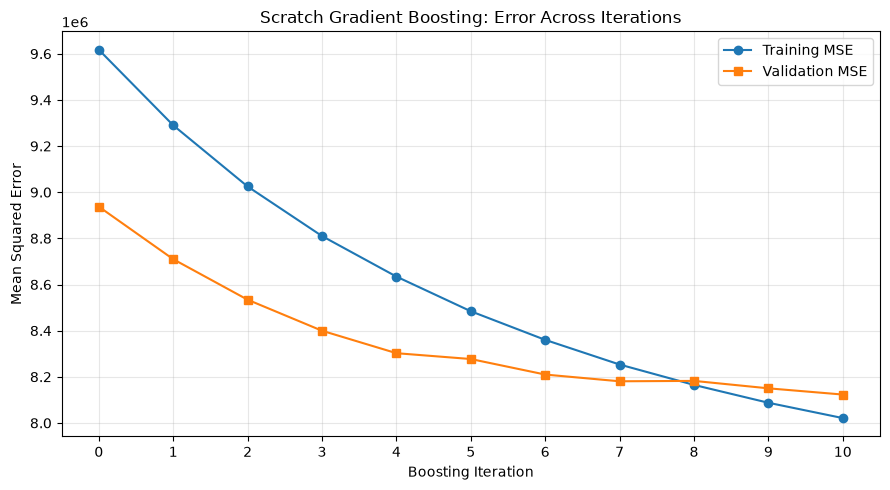

In [13]:
iterations = np.arange(
    0,
    N_ITERATIONS_SCRATCH + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    iterations,
    training_mse_history,
    marker="o",
    label="Training MSE"
)

plt.plot(
    iterations,
    validation_mse_history,
    marker="s",
    label="Validation MSE"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Scratch Gradient Boosting: Error Across Iterations")
plt.xticks(iterations)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

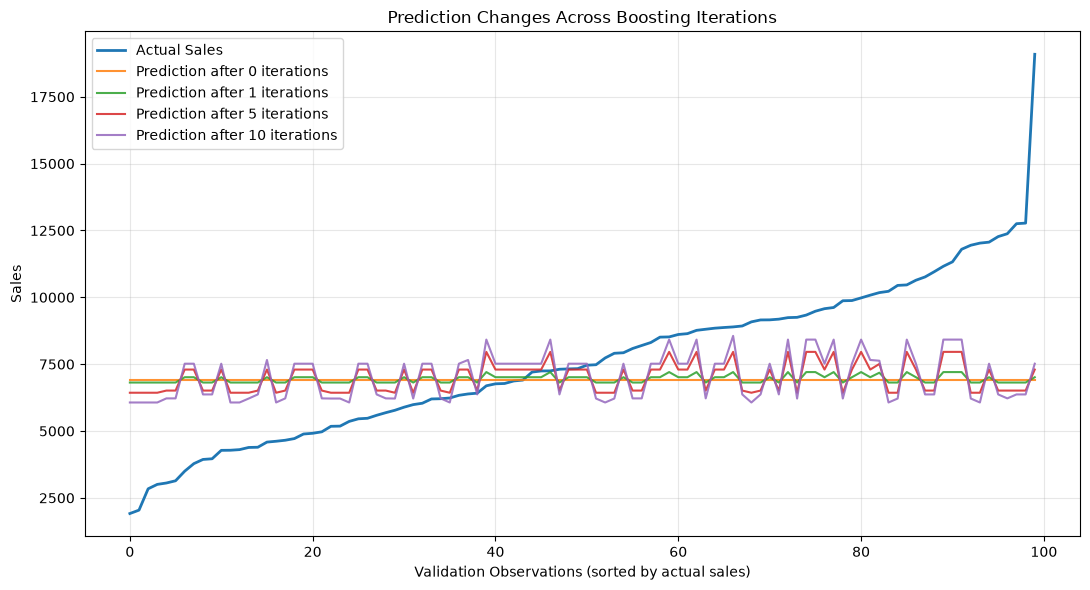

In [14]:
n_plot = min(100, len(X_validation_model))

X_plot = X_validation_model.iloc[:n_plot]
y_plot = y_validation_model.iloc[:n_plot].to_numpy(dtype=float)

prediction_snapshots = {
    0: np.full(n_plot, initial_prediction, dtype=float)
}

current_plot_predictions = np.full(
    n_plot,
    initial_prediction,
    dtype=float
)

for iteration, tree in enumerate(scratch_trees, start=1):

    current_plot_predictions += (
        LEARNING_RATE_SCRATCH * tree.predict(X_plot)
    )

    if iteration in [1, 5, 10]:
        prediction_snapshots[iteration] = (
            current_plot_predictions.copy()
        )

# Sort by actual sales to make the plot easier to read.
sort_indices = np.argsort(y_plot)

plt.figure(figsize=(11, 6))

plt.plot(
    y_plot[sort_indices],
    label="Actual Sales",
    linewidth=2
)

for iteration in [0, 1, 5, 10]:
    plt.plot(
        prediction_snapshots[iteration][sort_indices],
        label=f"Prediction after {iteration} iterations",
        alpha=0.85
    )

plt.xlabel("Validation Observations (sorted by actual sales)")
plt.ylabel("Sales")
plt.title("Prediction Changes Across Boosting Iterations")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
def evaluate_regression_model(
    model_name,
    y_true,
    y_pred,
    training_time=None
):
    """Calculate regression metrics for a fitted model."""

    results = {
        "Model": model_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),
        "R2": r2_score(
            y_true, y_pred
        )
    }

    if training_time is not None:
        results["Training_Time_Seconds"] = training_time

    return results

In [16]:
from itertools import product

TUNING_TRAIN_ROWS = 30_000
TUNING_VALIDATION_ROWS = 8_000

X_tune_train, y_tune_train = sample_xy(
    X_train_model,
    y_train_model,
    TUNING_TRAIN_ROWS
)

X_tune_validation, y_tune_validation = sample_xy(
    X_validation_model,
    y_validation_model,
    TUNING_VALIDATION_ROWS
)

n_estimators_values = [50, 100, 200]
learning_rate_values = [0.01, 0.1, 0.2]
max_depth_values = [3, 5]

tuning_results = []

for n_estimators, learning_rate, max_depth in product(
    n_estimators_values,
    learning_rate_values,
    max_depth_values
):

    model = GradientBoostingRegressor(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        loss="squared_error",
        random_state=RANDOM_STATE
    )

    start_time = time.perf_counter()

    model.fit(
        X_tune_train,
        y_tune_train
    )

    training_time = time.perf_counter() - start_time

    validation_predictions = model.predict(
        X_tune_validation
    )

    results = evaluate_regression_model(
        model_name=(
            f"GB_n{n_estimators}_lr{learning_rate}_d{max_depth}"
        ),
        y_true=y_tune_validation,
        y_pred=validation_predictions,
        training_time=training_time
    )

    results.update({
        "n_estimators": n_estimators,
        "learning_rate": learning_rate,
        "max_depth": max_depth
    })

    tuning_results.append(results)

    print(
        f"Trees={n_estimators:3d}, "
        f"LR={learning_rate:.2f}, "
        f"Depth={max_depth}, "
        f"Validation RMSE={results['RMSE']:,.2f}"
    )

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("\nTop 10 parameter combinations:")
display(tuning_df.head(10))

Trees= 50, LR=0.01, Depth=3, Validation RMSE=2,842.76
Trees= 50, LR=0.01, Depth=5, Validation RMSE=2,799.23
Trees= 50, LR=0.10, Depth=3, Validation RMSE=2,615.62
Trees= 50, LR=0.10, Depth=5, Validation RMSE=2,388.16
Trees= 50, LR=0.20, Depth=3, Validation RMSE=2,496.49
Trees= 50, LR=0.20, Depth=5, Validation RMSE=2,108.91
Trees=100, LR=0.01, Depth=3, Validation RMSE=2,794.29
Trees=100, LR=0.01, Depth=5, Validation RMSE=2,716.06
Trees=100, LR=0.10, Depth=3, Validation RMSE=2,506.54
Trees=100, LR=0.10, Depth=5, Validation RMSE=2,142.17
Trees=100, LR=0.20, Depth=3, Validation RMSE=2,292.08
Trees=100, LR=0.20, Depth=5, Validation RMSE=1,768.01
Trees=200, LR=0.01, Depth=3, Validation RMSE=2,745.57
Trees=200, LR=0.01, Depth=5, Validation RMSE=2,639.79
Trees=200, LR=0.10, Depth=3, Validation RMSE=2,306.51
Trees=200, LR=0.10, Depth=5, Validation RMSE=1,775.75
Trees=200, LR=0.20, Depth=3, Validation RMSE=2,018.35
Trees=200, LR=0.20, Depth=5, Validation RMSE=1,429.15

Top 10 parameter combinatio

,Model,RMSE,MAE,R2,Training_Time_Seconds,n_estimators,learning_rate,max_depth
0,GB_n200_lr0.2_d5,1429.153301,1052.038023,0.767049,19.014022,200,0.2,5
1,GB_n100_lr0.2_d5,1768.011125,1297.132829,0.643486,10.383201,100,0.2,5
2,GB_n200_lr0.1_d5,1775.745733,1296.167310,0.640360,22.353411,200,0.1,5
3,GB_n200_lr0.2_d3,2018.345606,1460.525813,0.535380,12.013584,200,0.2,3
4,GB_n50_lr0.2_d5,2108.912867,1536.457230,0.492748,5.260576,50,0.2,5
5,GB_n100_lr0.1_d5,2142.165149,1555.666678,0.476626,9.821487,100,0.1,5
6,GB_n100_lr0.2_d3,2292.084461,1653.500138,0.400806,6.188584,100,0.2,3
7,GB_n200_lr0.1_d3,2306.508521,1665.620685,0.393240,12.891411,200,0.1,3
8,GB_n50_lr0.1_d5,2388.160270,1727.333629,0.349521,5.642357,50,0.1,5
9,GB_n50_lr0.2_d3,2496.485607,1795.203097,0.289172,3.249267,50,0.2,3


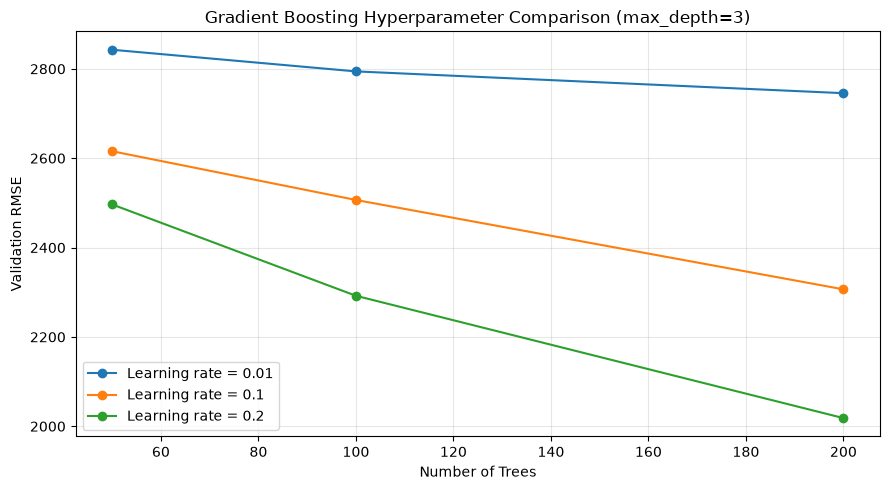

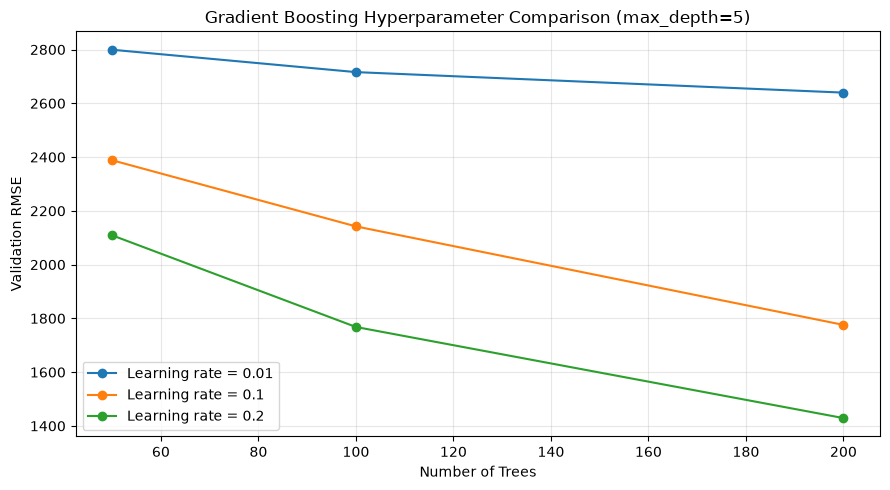

In [17]:
for depth in max_depth_values:

    subset = tuning_df[
        tuning_df["max_depth"] == depth
    ]

    plt.figure(figsize=(9, 5))

    for learning_rate in learning_rate_values:

        curve = subset[
            subset["learning_rate"] == learning_rate
        ].sort_values("n_estimators")

        plt.plot(
            curve["n_estimators"],
            curve["RMSE"],
            marker="o",
            label=f"Learning rate = {learning_rate}"
        )

    plt.xlabel("Number of Trees")
    plt.ylabel("Validation RMSE")
    plt.title(
        f"Gradient Boosting Hyperparameter Comparison "
        f"(max_depth={depth})"
    )

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [18]:
learning_curve_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    loss="squared_error",
    random_state=RANDOM_STATE
)

start_time = time.perf_counter()

learning_curve_model.fit(
    X_tune_train,
    y_tune_train
)

learning_curve_training_time = (
    time.perf_counter() - start_time
)

train_errors = []
validation_errors = []

for predictions in learning_curve_model.staged_predict(
    X_tune_train
):
    train_errors.append(
        mean_squared_error(
            y_tune_train,
            predictions
        )
    )

for predictions in learning_curve_model.staged_predict(
    X_tune_validation
):
    validation_errors.append(
        mean_squared_error(
            y_tune_validation,
            predictions
        )
    )

tree_counts = np.arange(
    1,
    len(train_errors) + 1
)

print(
    "Learning curve model training time:",
    round(learning_curve_training_time, 2),
    "seconds"
)

Learning curve model training time: 10.39 seconds


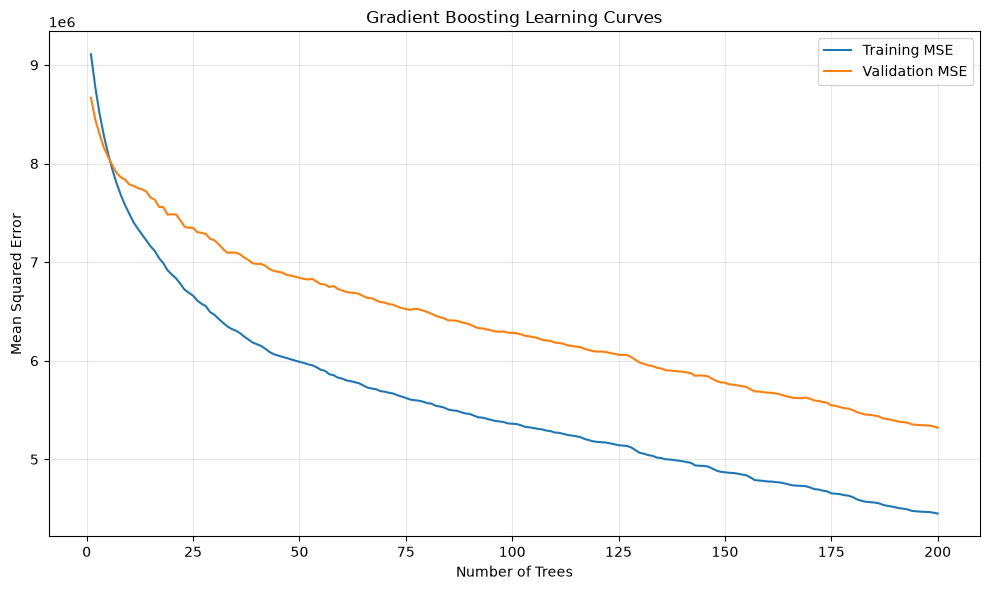

In [19]:
plt.figure(figsize=(10, 6))

plt.plot(
    tree_counts,
    train_errors,
    label="Training MSE"
)

plt.plot(
    tree_counts,
    validation_errors,
    label="Validation MSE"
)

plt.xlabel("Number of Trees")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Boosting Learning Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
best_stage_index = int(np.argmin(validation_errors))

best_tree_count = best_stage_index + 1
best_validation_mse = validation_errors[best_stage_index]

print("Best tree count:", best_tree_count)
print("Lowest validation MSE:", round(best_validation_mse, 2))
print(
    "Validation RMSE at best stage:",
    round(np.sqrt(best_validation_mse), 2)
)

Best tree count: 200
Lowest validation MSE: 5319981.56
Validation RMSE at best stage: 2306.51


In [21]:
learning_rate_experiments = {
    "LR_0.1_Trees_100": {
        "learning_rate": 0.1,
        "n_estimators": 100
    },
    "LR_0.01_Trees_500": {
        "learning_rate": 0.01,
        "n_estimators": 500
    }
}

learning_rate_results = []
learning_rate_models = {}

for model_name, params in learning_rate_experiments.items():

    model = GradientBoostingRegressor(
        learning_rate=params["learning_rate"],
        n_estimators=params["n_estimators"],
        max_depth=3,
        loss="squared_error",
        random_state=RANDOM_STATE
    )

    start_time = time.perf_counter()

    model.fit(
        X_tune_train,
        y_tune_train
    )

    training_time = time.perf_counter() - start_time

    validation_predictions = model.predict(
        X_tune_validation
    )

    result = evaluate_regression_model(
        model_name=model_name,
        y_true=y_tune_validation,
        y_pred=validation_predictions,
        training_time=training_time
    )

    result.update(params)

    learning_rate_results.append(result)
    learning_rate_models[model_name] = model

learning_rate_comparison = pd.DataFrame(
    learning_rate_results
)

display(learning_rate_comparison)

,Model,RMSE,MAE,R2,Training_Time_Seconds,learning_rate,n_estimators
0,LR_0.1_Trees_100,2506.540427,1805.600374,0.283434,5.287126,0.10,100
1,LR_0.01_Trees_500,2626.150960,1883.222539,0.213415,24.983234,0.01,500


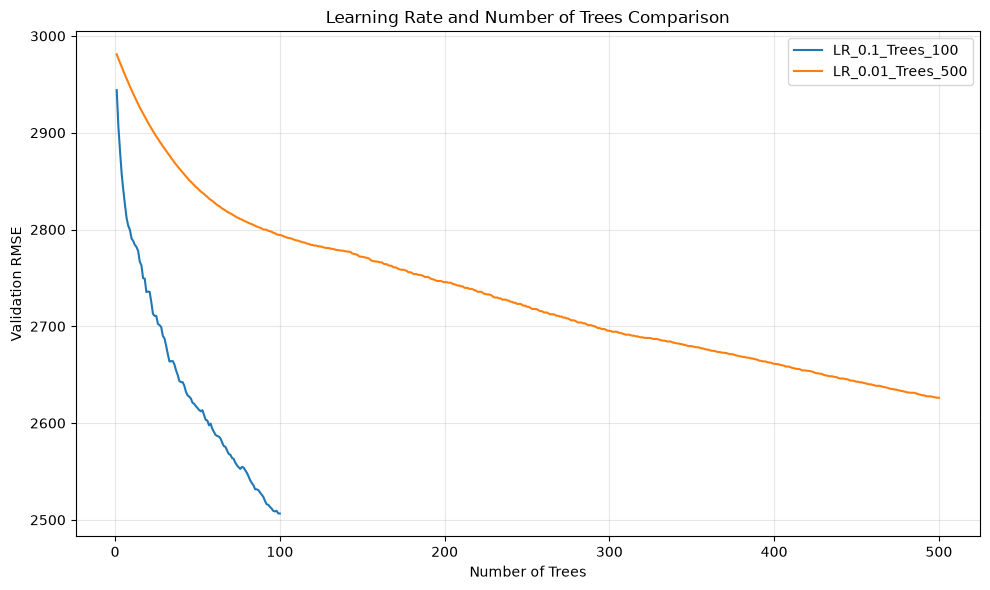

In [22]:
plt.figure(figsize=(10, 6))

for model_name, model in learning_rate_models.items():

    stage_errors = []

    for predictions in model.staged_predict(
        X_tune_validation
    ):
        stage_errors.append(
            mean_squared_error(
                y_tune_validation,
                predictions
            )
        )

    plt.plot(
        np.arange(1, len(stage_errors) + 1),
        np.sqrt(stage_errors),
        label=model_name
    )

plt.xlabel("Number of Trees")
plt.ylabel("Validation RMSE")
plt.title("Learning Rate and Number of Trees Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
decision_tree = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=20,
    random_state=RANDOM_STATE
)

random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    max_features=1.0,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

best_parameters = tuning_df.iloc[0]

gradient_boosting = GradientBoostingRegressor(
    n_estimators=int(best_parameters["n_estimators"]),
    learning_rate=float(best_parameters["learning_rate"]),
    max_depth=int(best_parameters["max_depth"]),
    loss="squared_error",
    random_state=RANDOM_STATE
)

models = {
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting
}

print("Selected Gradient Boosting parameters:")
print({
    "n_estimators": int(best_parameters["n_estimators"]),
    "learning_rate": float(best_parameters["learning_rate"]),
    "max_depth": int(best_parameters["max_depth"])
})

Selected Gradient Boosting parameters:
{'n_estimators': 200, 'learning_rate': 0.2, 'max_depth': 5}


In [24]:
validation_results = []
fitted_models = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    start_time = time.perf_counter()

    model.fit(
        X_train_model,
        y_train_model
    )

    training_time = time.perf_counter() - start_time

    validation_predictions = model.predict(
        X_validation_model
    )

    result = evaluate_regression_model(
        model_name=model_name,
        y_true=y_validation_model,
        y_pred=validation_predictions,
        training_time=training_time
    )

    validation_results.append(result)
    fitted_models[model_name] = model

    print(
        f"Completed in {training_time:.2f} seconds | "
        f"Validation RMSE: {result['RMSE']:,.2f}"
    )

validation_comparison = pd.DataFrame(
    validation_results
).sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

display(validation_comparison)

Training Decision Tree...
Completed in 0.89 seconds | Validation RMSE: 2,124.80
Training Random Forest...
Completed in 23.45 seconds | Validation RMSE: 1,441.52
Training Gradient Boosting...
Completed in 62.19 seconds | Validation RMSE: 1,361.04


,Model,RMSE,MAE,R2,Training_Time_Seconds
0,Gradient Boosting,1361.041675,1011.231260,0.789300,62.190516
1,Random Forest,1441.522621,1023.329229,0.763645,23.447411
2,Decision Tree,2124.797495,1523.849072,0.486481,0.887896


In [25]:
test_results = []
test_predictions = {}

for model_name, model in fitted_models.items():

    predictions = model.predict(
        X_test_model
    )

    test_predictions[model_name] = predictions

    result = evaluate_regression_model(
        model_name=model_name,
        y_true=y_test_model,
        y_pred=predictions
    )

    test_results.append(result)

test_comparison = pd.DataFrame(
    test_results
).sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

display(test_comparison)

,Model,RMSE,MAE,R2
0,Gradient Boosting,1342.986469,972.666188,0.813339
1,Random Forest,1447.500426,986.072734,0.783156
2,Decision Tree,2072.724778,1467.075898,0.555375


In [26]:
importance_frames = {}

for model_name, model in fitted_models.items():

    importance_df = pd.DataFrame({
        "Feature": X_train_model.columns,
        "Importance": model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    importance_frames[model_name] = importance_df

    print(f"\nTop 10 features — {model_name}")

    display(importance_df.head(10))


Top 10 features — Decision Tree


,Feature,Importance
0,Promo,0.221631
1,CompetitionDistance,0.169473
2,Store,0.117220
3,DayOfWeek,0.069430
4,CompetitionOpenSinceYear,0.060476
5,CompetitionOpenSinceMonth,0.049387
6,WeekOfYear,0.047616
7,StoreType_b,0.041066
8,Promo2SinceWeek,0.033350
9,Promo2SinceYear,0.026730



Top 10 features — Random Forest


,Feature,Importance
0,CompetitionDistance,0.188813
1,Promo,0.164565
2,Store,0.145844
3,CompetitionOpenSinceYear,0.078343
4,CompetitionOpenSinceMonth,0.066714
5,DayOfWeek,0.065743
6,WeekOfYear,0.037087
7,Day,0.034303
8,Promo2SinceWeek,0.033829
9,StoreType_b,0.031279



Top 10 features — Gradient Boosting


,Feature,Importance
0,Store,0.202149
1,CompetitionDistance,0.181381
2,Promo,0.167380
3,DayOfWeek,0.057144
4,CompetitionOpenSinceYear,0.056373
5,CompetitionOpenSinceMonth,0.051258
6,WeekOfYear,0.039661
7,Day,0.033065
8,StoreType_b,0.032914
9,Promo2SinceWeek,0.031254


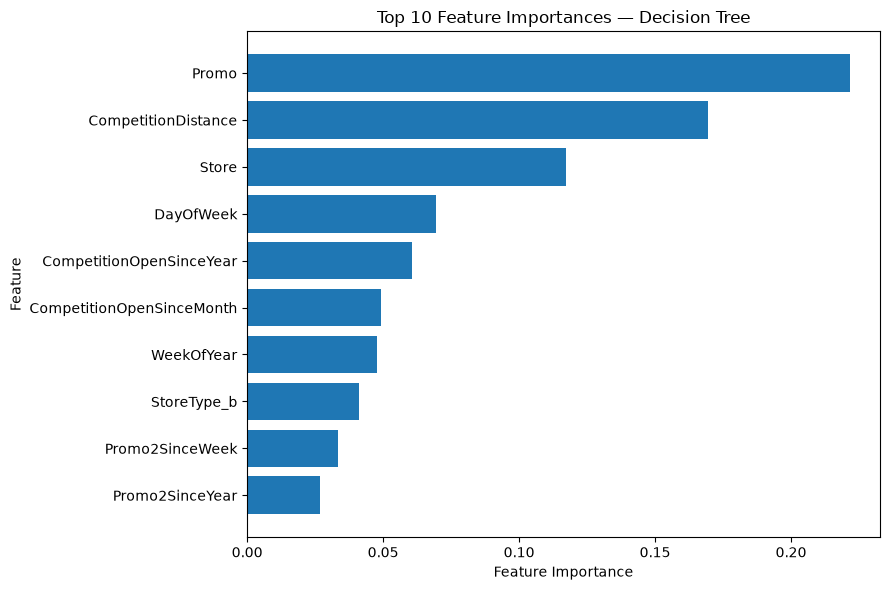

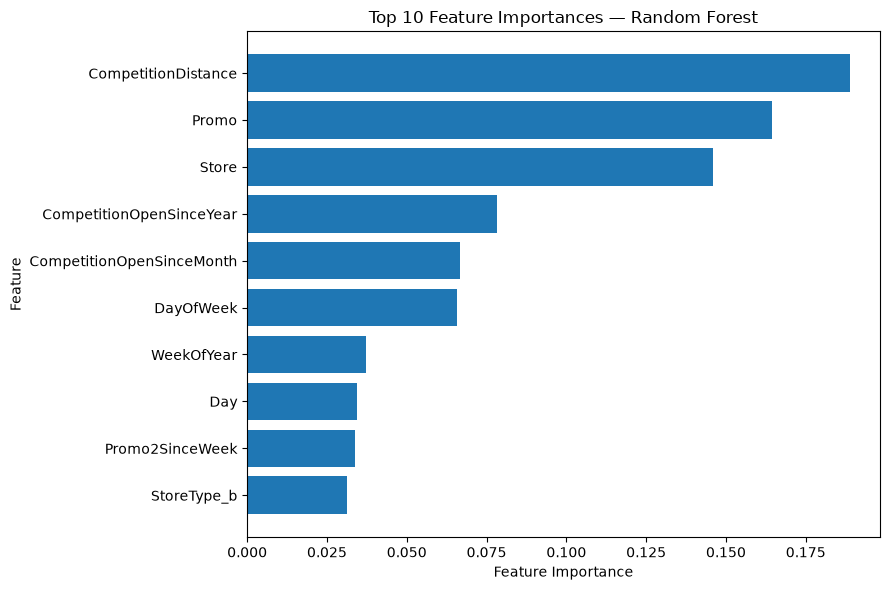

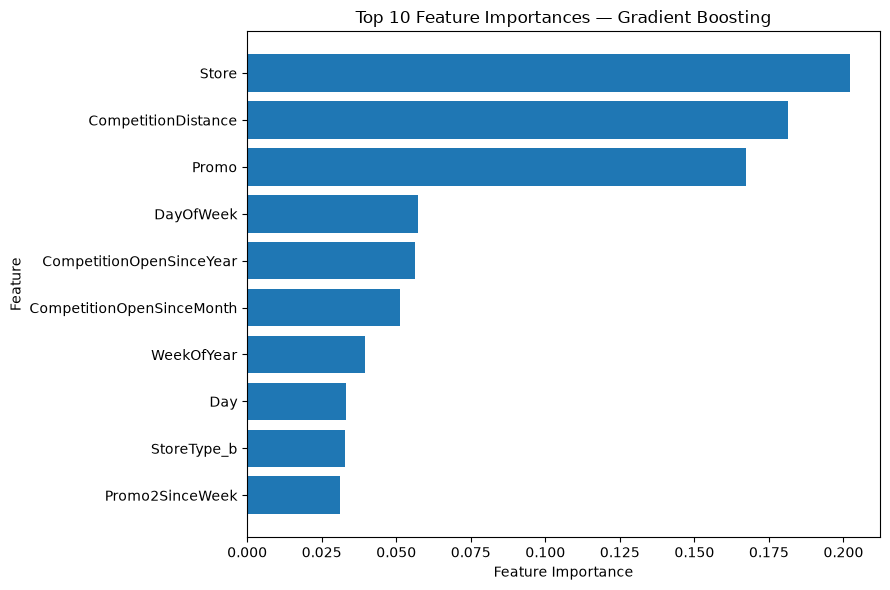

In [27]:
for model_name, importance_df in importance_frames.items():

    top_features = importance_df.head(10).sort_values(
        "Importance",
        ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(f"Top 10 Feature Importances — {model_name}")

    plt.tight_layout()
    plt.show()

In [28]:
top_feature_sets = {
    model_name: set(
        importance_df.head(10)["Feature"]
    )
    for model_name, importance_df in importance_frames.items()
}

all_top_features = set.union(
    *top_feature_sets.values()
)

consistency_rows = []

for feature in all_top_features:

    models_in_top_10 = [
        model_name
        for model_name, features in top_feature_sets.items()
        if feature in features
    ]

    consistency_rows.append({
        "Feature": feature,
        "Models_in_Top_10": len(models_in_top_10),
        "Important_in_Models": ", ".join(models_in_top_10)
    })

consistency_df = pd.DataFrame(
    consistency_rows
).sort_values(
    ["Models_in_Top_10", "Feature"],
    ascending=[False, True]
).reset_index(drop=True)

display(consistency_df)

,Feature,Models_in_Top_10,Important_in_Models
0,CompetitionDistance,3,"Decision Tree, Random Forest, Gradient Boosting"
1,CompetitionOpenSinceMonth,3,"Decision Tree, Random Forest, Gradient Boosting"
2,CompetitionOpenSinceYear,3,"Decision Tree, Random Forest, Gradient Boosting"
3,DayOfWeek,3,"Decision Tree, Random Forest, Gradient Boosting"
4,Promo,3,"Decision Tree, Random Forest, Gradient Boosting"
5,Promo2SinceWeek,3,"Decision Tree, Random Forest, Gradient Boosting"
6,Store,3,"Decision Tree, Random Forest, Gradient Boosting"
7,StoreType_b,3,"Decision Tree, Random Forest, Gradient Boosting"
8,WeekOfYear,3,"Decision Tree, Random Forest, Gradient Boosting"
9,Day,2,"Random Forest, Gradient Boosting"


In [36]:
try:
    from xgboost import XGBRegressor

    XGBOOST_AVAILABLE = True
    print("XGBoost is installed.")

except ImportError:
    XGBOOST_AVAILABLE = False
    print(
        "XGBoost is not installed. "
        "Install it in your notebook environment to run the optional experiment."
    )

XGBoost is installed.


In [37]:
if XGBOOST_AVAILABLE:

    xgboost_model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    start_time = time.perf_counter()

    xgboost_model.fit(
        X_tune_train,
        y_tune_train
    )

    xgboost_training_time = (
        time.perf_counter() - start_time
    )

    xgboost_validation_predictions = (
        xgboost_model.predict(
            X_tune_validation
        )
    )

    xgboost_result = evaluate_regression_model(
        model_name="XGBoost",
        y_true=y_tune_validation,
        y_pred=xgboost_validation_predictions,
        training_time=xgboost_training_time
    )

    print("XGBoost validation results:")
    display(pd.DataFrame([xgboost_result]))

else:
    print("Skipping XGBoost because it is not installed.")

XGBoost validation results:


,Model,RMSE,MAE,R2,Training_Time_Seconds
0,XGBoost,1721.645434,1250.545654,0.66194,1.00904


In [33]:
validation_report = validation_comparison.rename(
    columns={
        "RMSE": "Validation_RMSE",
        "MAE": "Validation_MAE",
        "R2": "Validation_R2",
        "Training_Time_Seconds": "Training_Time_Seconds"
    }
)

test_report = test_comparison.rename(
    columns={
        "RMSE": "Test_RMSE",
        "MAE": "Test_MAE",
        "R2": "Test_R2"
    }
)

final_comparison = validation_report.merge(
    test_report[
        ["Model", "Test_RMSE", "Test_MAE", "Test_R2"]
    ],
    on="Model",
    how="left"
)

final_comparison = final_comparison.sort_values(
    "Validation_RMSE",
    ascending=True
).reset_index(drop=True)

display(final_comparison)

,Model,Validation_RMSE,Validation_MAE,Validation_R2,Training_Time_Seconds,Test_RMSE,Test_MAE,Test_R2
0,Gradient Boosting,1361.041675,1011.231260,0.789300,62.190516,1342.986469,972.666188,0.813339
1,Random Forest,1441.522621,1023.329229,0.763645,23.447411,1447.500426,986.072734,0.783156
2,Decision Tree,2124.797495,1523.849072,0.486481,0.887896,2072.724778,1467.075898,0.555375


In [34]:
tuning_df.to_csv(
    OUTPUT_DIR / "gradient_boosting_tuning_results.csv",
    index=False
)

learning_rate_comparison.to_csv(
    OUTPUT_DIR / "learning_rate_comparison.csv",
    index=False
)

validation_comparison.to_csv(
    OUTPUT_DIR / "validation_model_comparison.csv",
    index=False
)

test_comparison.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv",
    index=False
)

final_comparison.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

consistency_df.to_csv(
    OUTPUT_DIR / "feature_importance_consistency.csv",
    index=False
)

for model_name, importance_df in importance_frames.items():

    safe_name = model_name.lower().replace(" ", "_")

    importance_df.to_csv(
        OUTPUT_DIR / f"{safe_name}_feature_importance.csv",
        index=False
    )

print("All comparison tables saved successfully.")

All comparison tables saved successfully.


In [35]:
import joblib

best_model_name = validation_comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

model_artifact = {
    "model": best_model,
    "feature_columns": X_train_model.columns.tolist(),
    "model_name": best_model_name,
    "target": "Sales",
    "excluded_features": [
        "Customers",
        "Date",
        "Open"
    ]
}

joblib.dump(
    model_artifact,
    OUTPUT_DIR / "best_sales_forecasting_model.joblib"
)

print("Best model selected using validation RMSE:", best_model_name)

print(
    "Saved model:",
    OUTPUT_DIR / "best_sales_forecasting_model.joblib"
)

Best model selected using validation RMSE: Gradient Boosting
Saved model: e:\vs\module 4\Sales Forecasting with Gradient Boosting\outputs\best_sales_forecasting_model.joblib
